# Kenya County Crop Mix (Pilot)

Each annual crop's share of cropland in 14 counties, with errors. A free sample from [NuaSense](https://agriculture-data.com), East African agricultural data; also on [Hugging Face](https://huggingface.co/datasets/nuasense/kenya-county-crop-mix-pilot) (CC BY-NC 4.0).

In [1]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True, "font.size": 10})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

def load(name, hf_url):
    # On Kaggle the CSV sits under /kaggle/input; in Colab or on your machine the same table
    # is read straight from Hugging Face.
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"**/{name}", recursive=True)
    return pd.read_csv(hits[0]) if hits else pd.read_parquet(hf_url)

df = load("kenya_county_crop_mix_pilot.csv", "https://huggingface.co/datasets/nuasense/kenya-county-crop-mix-pilot/resolve/main/data/crop_mix/crop_mix.parquet")
print(f"{len(df):,} rows")
df.head()

126 rows


,country,county_id,county_name,county_cropland_share,crop,share,standard_error,share_raw,sample_points,reliable,estimated_on
0,KE,bungoma,Bungoma,0.5329,maize,0.5550,0.4610,0.7037,100,False,2026-09-15
1,KE,bungoma,Bungoma,0.5329,wheat,0.1461,0.2444,0.1852,100,False,2026-09-15
2,KE,bungoma,Bungoma,0.5329,fallow,0.1257,0.0647,0.0000,100,False,2026-09-15
3,KE,bungoma,Bungoma,0.5329,peas,0.0856,0.0743,0.0000,100,False,2026-09-15
4,KE,bungoma,Bungoma,0.5329,potato,0.0584,0.0000,0.0741,100,False,2026-09-15


## Only the reliable estimates

A pilot with wide error bars: read `reliable` first, and trust the ranking more than the decimals.

In [2]:
rel = df[df.reliable & (df.share > 0)].sort_values(["county_name", "share"], ascending=[True, False])
rel[["county_name", "crop", "share", "standard_error", "sample_points"]]

,county_name,crop,share,standard_error,sample_points
5,Bungoma,beans,0.0292,0.0096,100
19,Kakamega,potato,0.0554,0.0144,94
20,Kakamega,wheat,0.0554,0.0146,94
21,Kakamega,beans,0.0277,0.0053,94
36,Kiambu,fallow,0.5465,0.2211,55
37,Kiambu,vegetables,0.2204,0.0874,55
38,Kiambu,maize,0.1101,0.0218,55
41,Kiambu,potato,0.0220,0.0050,55
45,Kirinyaga,fallow,0.3563,0.0610,114
46,Kirinyaga,peas,0.3283,0.0792,114


## Maize share with its error

Corrected maize share of the cropland per county, plus or minus one standard error.

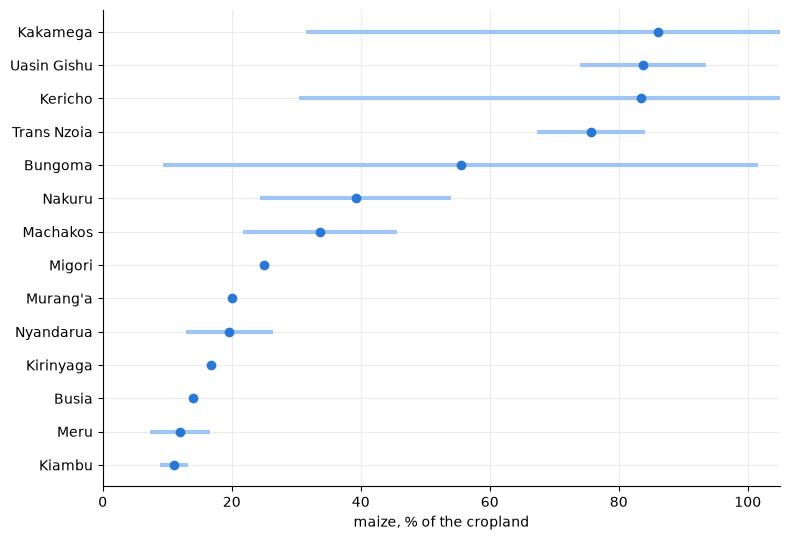

In [3]:
mz = df[df.crop == "maize"].sort_values("share")
plt.figure(figsize=(8, 5.5))
plt.errorbar(mz.share * 100, mz.county_name, xerr=mz.standard_error * 100, fmt="o", color=BLUE, ecolor="#9ec5f4", elinewidth=3, capsize=0)
plt.xlabel("maize, % of the cropland"); plt.xlim(0, 105)
plt.tight_layout(); plt.show()

## Corrected against raw

How much the confusion-matrix correction moves each crop, on average.

In [4]:
df.assign(moved=(df.share - df.share_raw) * 100).groupby("crop").moved.mean().round(1).sort_values()

crop
maize        -14.5
wheat         -4.9
beans         -2.2
potato        -1.9
fodder         0.1
millet         0.7
vegetables     3.2
peas           5.1
fallow        14.4
Name: moved, dtype: float64

## The full data

The NuaSense API serves each re-run as the sample and the labels grow, next to cropland extent, crop condition and prices per county.

```
pip install nuasense
```

A key with a free monthly allowance comes from [platform.nuasense.com](https://platform.nuasense.com/start). On Kaggle, store it as a secret named `NUASENSE_API_KEY` (Add-ons → Secrets). Fields and filters: [agriculture-data.com](https://agriculture-data.com/datasets/).

In [5]:
# Runs only when a NuaSense key is available (Kaggle secret NUASENSE_API_KEY or an environment variable).
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("NUASENSE_API_KEY", UserSecretsClient().get_secret("NUASENSE_API_KEY"))
except Exception:
    pass

if os.environ.get("NUASENSE_API_KEY"):
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nuasense"], check=False)
    import nuasense
    ns = nuasense.Client()
    rows = ns.rows("/market/crop-mix", start="-2y", limit=100, county="nakuru")
    display(pd.DataFrame(rows))
else:
    print("No NUASENSE_API_KEY set: add it as a Kaggle secret (Add-ons -> Secrets) to read the full series.")

No NUASENSE_API_KEY set: add it as a Kaggle secret (Add-ons -> Secrets) to read the full series.
